# Uniqueness-aware feature engineering: prototype

Walkthrough of the six pipeline steps on synthetic data, using the `uafe` package in this folder.
The measures and the base generator are copied unchanged from `uniqueness-aware-feature-engineering-draft.ipynb`.
`run_prototype.py` runs the same steps from the command line.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np, pandas as pd
from IPython.display import Image, Markdown, display
from uafe import plots
from uafe.data import arrival_feature_names, generate_population
from uafe.pipeline import (assess_population, population_summary, calibrate, choose_threshold,
                           build_system, fit_instance_from_names, representation_report)
pd.set_option("display.width", 200)
OUT = "outputs_nb"; import os; os.makedirs(OUT, exist_ok=True)

## Phase I: data and assessment
**Step 1.** Draw reference representations $d_i$. The population is a long-tailed mix of shared features, features specific to subgroups A–D (60/25/10/5 %), and idiosyncratic features. The last 100 individuals are held back as new arrivals for Phase III. The arrivals also report brand-new features that no individual in the training data reported (`unseen_000` … `unseen_099`, 1.5 per arrival on average).

In [2]:
N_REF, N_NEW = 400, 100
full = generate_population(n=N_REF + N_NEW, seed=7)
reference = full.subset(np.arange(N_REF))
arrivals = full.subset(np.arange(N_REF, N_REF + N_NEW))
arrival_names = arrival_feature_names(arrivals)  # feature names per arrival, including brand-new ones
reference.X.shape

(400, 570)

**Step 2.** Compute $Pr_i$ (log10 and normalized), $j_{pop}$ (mean Jaccard to everyone else) and $Rare(d_i)$ for every individual.

In [3]:
assessment = assess_population(reference.X, reference.group)
summary = population_summary(reference.X, assessment)
display(pd.Series(summary))
assessment.groupby("group").median(numeric_only=True)

individuals                                   400
distinct features                             561
features per individual (median)             29.0
features held by a single individual           87
features held by <1% of individuals           228
individuals with a unique feature vector     100%
median j_pop                                0.132
median normalized Pr_i                        0.0
median Rare(d_i) (%)                         85.2
dtype: object

,n_features,log10_pr_i,pr_i_normalized,j_pop,rarity,unique_vector
group,,,,,,
A,29.0,-34.930213,1.380902e-11,0.138153,84.750,1.0
B,29.0,-37.085931,3.984241e-14,0.126267,88.000,1.0
C,31.0,-41.487711,4.299529e-17,0.119243,88.625,1.0
D,28.0,-41.023975,2.948657e-18,0.110540,88.250,1.0


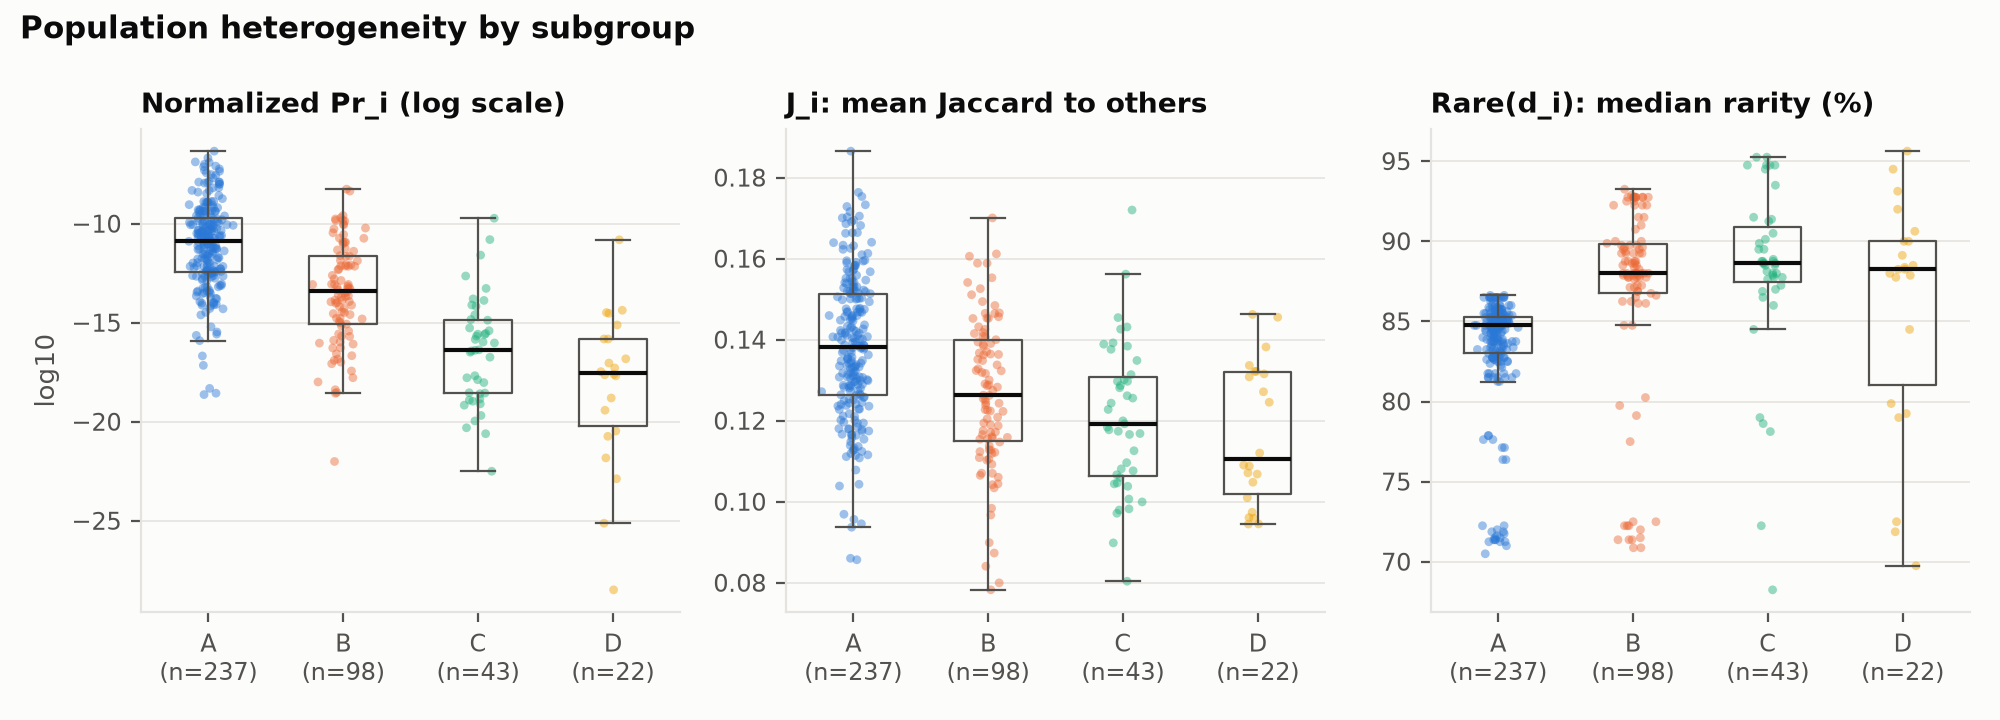

In [4]:
plots.plot_measures_by_group(assessment, f"{OUT}/measures.png")
Image(f"{OUT}/measures.png")

## Phase II: feature selection and training
**Steps 3–4.** For each prevalence threshold τ, keep the features with prevalence ≥ τ in the training folds, train a logistic regression, and measure held-out accuracy and $J_{system}$ (mean share of each held-out individual's features that the system keeps).

In [5]:
MIN_COVERAGE = 0.6
calibration = calibrate(reference.X, reference.y, reference.group)
tau = choose_threshold(calibration.summary, min_coverage=MIN_COVERAGE)
print("chosen tau:", tau)
calibration.summary.round(3)

chosen tau: 0.02


,tau,n_selected,j_system,j_p10,accuracy,accuracy_sd,j_A,j_B,j_C,j_D,acc_A,acc_B,acc_C,acc_D,j_worst_group
0,0.000,539.0,0.989,0.963,0.688,0.031,0.989,0.987,0.992,0.989,0.709,0.633,0.674,0.727,0.987
1,0.002,539.0,0.989,0.963,0.688,0.031,0.989,0.987,0.992,0.989,0.709,0.633,0.674,0.727,0.987
2,0.005,438.4,0.972,0.935,0.690,0.040,0.972,0.972,0.974,0.963,0.722,0.612,0.674,0.727,0.963
3,0.010,292.8,0.937,0.885,0.708,0.047,0.943,0.945,0.936,0.838,0.730,0.633,0.744,0.727,0.838
4,0.020,235.6,0.918,0.850,0.717,0.046,0.935,0.939,0.880,0.708,0.734,0.633,0.814,0.727,0.708
5,0.030,210.0,0.893,0.750,0.710,0.037,0.923,0.929,0.762,0.673,0.726,0.643,0.791,0.682,0.673
6,0.050,150.0,0.811,0.640,0.682,0.057,0.854,0.843,0.608,0.608,0.726,0.582,0.721,0.591,0.608
7,0.075,103.8,0.726,0.533,0.688,0.060,0.822,0.599,0.565,0.576,0.700,0.663,0.674,0.682,0.565
8,0.100,94.8,0.700,0.500,0.670,0.053,0.804,0.553,0.540,0.552,0.696,0.602,0.698,0.636,0.540
9,0.150,46.6,0.491,0.364,0.630,0.071,0.539,0.422,0.420,0.426,0.641,0.582,0.721,0.545,0.420


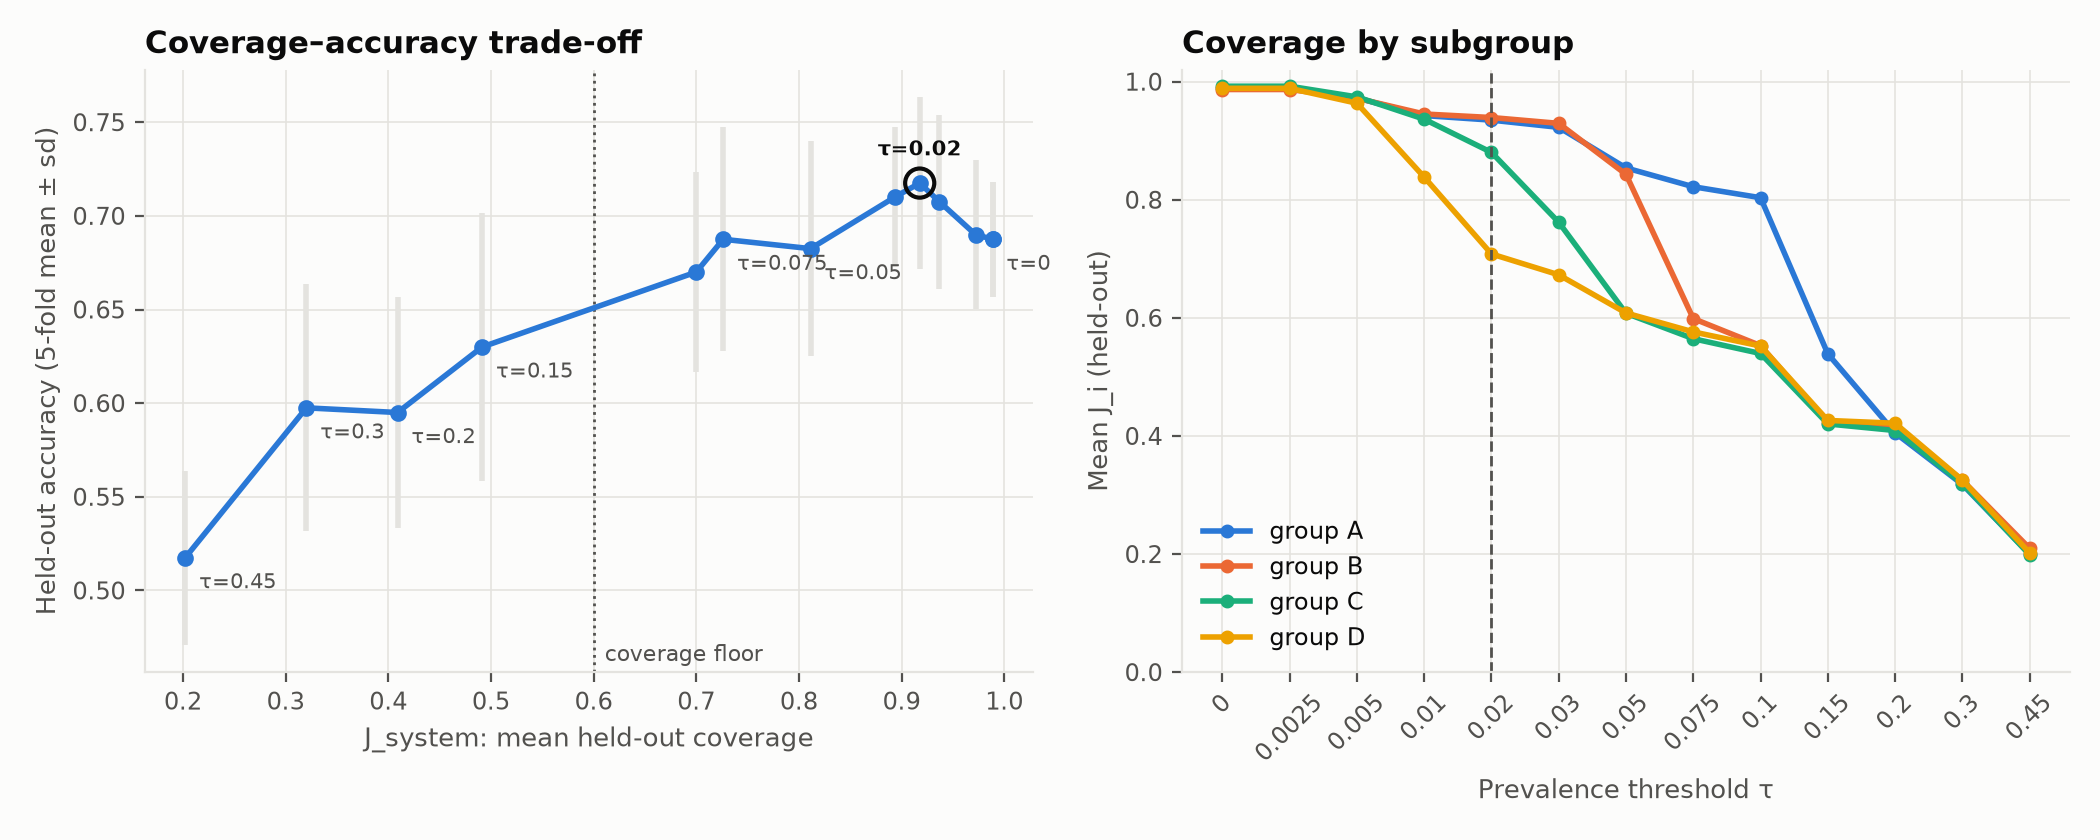

In [6]:
groups = sorted(set(reference.group))
plots.plot_calibration(calibration.summary, tau, groups, f"{OUT}/calibration.png", min_coverage=MIN_COVERAGE)
Image(f"{OUT}/calibration.png")

## Phase III: deployment
**Step 6.** Score each new arrival from the feature names it reports: fit score $j_{sys}$ and its percentile, $Pr_i$, rarity, and the features the system drops. Features no training individual reported count as reported but not kept, so they lower the fit score; in $Pr_i$ and rarity they count as held by that arrival alone, and the model ignores them. The deployed system is not changed.

In [7]:
system = build_system(reference, assessment, calibration, tau)
reports = [fit_instance_from_names(system, names, instance_id=f"new_{i:03d}")[0]
           for i, names in enumerate(arrival_names)]
arrival_df = pd.DataFrame([r.to_dict() for r in reports]).assign(group=arrivals.group, y=arrivals.y)
print(f"arrivals with never-seen features: {(arrival_df['n_unseen'] > 0).mean():.0%}")
display(pd.crosstab(arrival_df["group"], arrival_df["band"]))
display(pd.crosstab(arrival_df["n_unseen"].clip(upper=3), arrival_df["band"]).rename_axis("never-seen features (3 = 3+)"))
display(Markdown(min(reports, key=lambda r: r.fit_score).to_markdown()))

arrivals with never-seen features: 79%


band,partially represented,poorly represented,well represented
group,,,
A,31,0,32
B,10,0,17
C,6,0,1
D,1,2,0


band,partially represented,poorly represented,well represented
never-seen features (3 = 3+),,,
0,3,0,18
1,11,0,22
2,19,2,10
3,15,0,0


#### Fit report: new_074

- **Fit score (j_sys)**: 0.69, at the 2nd percentile of the pooled population. **poorly represented**
- Features the system keeps: 20 of 29 reported
- Collision probability: log10 Pr_i = -43.4; normalized Pr_i = 1.98e-20 (3rd percentile)
- Rarity Rare(d_i): 87.3% (72nd percentile)
- Features the system omits: groupD_11, groupD_13, groupD_14, groupD_16, groupD_18, groupD_19, idio_139, unseen_015, unseen_020
- Features no training individual reported: unseen_015, unseen_020

**Effect of never-seen features on one arrival.** The first arrival that reports brand-new features is scored twice: once with only the features the pooled population also has, and once with everything it reports.

In [8]:
i = next(k for k, r in enumerate(reports) if r.unseen_features)
names = arrival_names[i]
known_only, _ = fit_instance_from_names(system, [f for f in names if f in set(system.feature_names)],
                                        instance_id=f"new_{i:03d} (without brand-new features)")
everything, unseen = fit_instance_from_names(system, names, instance_id=f"new_{i:03d}")
print("brand-new features:", unseen)
cols = ["instance_id", "n_reported", "n_represented", "n_unseen", "fit_score", "fit_percentile", "band",
        "log10_pr_i", "rarity", "prediction"]
display(pd.DataFrame([known_only.to_dict(), everything.to_dict()])[cols].round(3))
display(Markdown(everything.to_markdown()))

brand-new features: ['unseen_006', 'unseen_086']


,instance_id,n_reported,n_represented,n_unseen,fit_score,fit_percentile,band,log10_pr_i,rarity,prediction
0,new_000 (without brand-new features),33,30,0,0.909,29.375,well represented,-39.034,85.037,0
1,new_000,35,30,2,0.857,11.250,partially represented,-44.100,85.037,0


#### Fit report: new_000

- **Fit score (j_sys)**: 0.86, at the 11th percentile of the pooled population. **partially represented**
- Features the system keeps: 30 of 35 reported
- Collision probability: log10 Pr_i = -44.1; normalized Pr_i = 4.43e-17 (14th percentile)
- Rarity Rare(d_i): 85.0% (48th percentile)
- Features the system omits: idio_048, idio_227, idio_237, unseen_006, unseen_086
- Features no training individual reported: unseen_006, unseen_086

**Step 5.** Write the structured representation report.

In [9]:
report = representation_report(summary, system, calibration, MIN_COVERAGE,
                               feature_kind=reference.feature_kind, arrivals=arrivals, arrival_reports=reports)
Markdown(report)

# Representation report

## 1. Pooled population (Phase I)

- **individuals**: 400
- **distinct features**: 561
- **features per individual (median)**: 29.0
- **features held by a single individual**: 87
- **features held by <1% of individuals**: 228
- **individuals with a unique feature vector**: 100%
- **median j_pop**: 0.132
- **median normalized Pr_i**: 7.12e-13
- **median Rare(d_i) (%)**: 85.2

Heterogeneity measures by subgroup:

| group | n | features_median | log10_pr_i_median | log10_pr_i_norm_median | j_pop_mean | rarity_median | unique_share |
|---|---|---|---|---|---|---|---|
| A | 237 | 29 | -34.9 | -10.9 | 0.138 | 84.8 | 100% |
| B | 98 | 29 | -37.1 | -13.4 | 0.127 | 88.0 | 100% |
| C | 43 | 31 | -41.5 | -16.4 | 0.120 | 88.6 | 100% |
| D | 22 | 28 | -41.0 | -17.5 | 0.117 | 88.2 | 100% |

## 2. Feature selection & calibration (Phase II)

The prevalence threshold was swept with 5-fold cross-validation. The chosen threshold is **τ = 0.02**: it has the highest held-out accuracy among thresholds with J_system ≥ 0.6.

| tau | n_selected | j_system | j_worst_group | accuracy | accuracy_sd |
|---|---|---|---|---|---|
| 0 | 539 | 0.989 | 0.987 | 0.688 | 0.031 |
| 0.0025 | 539 | 0.989 | 0.987 | 0.688 | 0.031 |
| 0.005 | 438 | 0.972 | 0.963 | 0.690 | 0.040 |
| 0.01 | 293 | 0.937 | 0.838 | 0.708 | 0.047 |
| 0.02 | 236 | 0.918 | 0.708 | 0.717 | 0.046 |
| 0.03 | 210 | 0.893 | 0.673 | 0.710 | 0.037 |
| 0.05 | 150 | 0.811 | 0.608 | 0.682 | 0.057 |
| 0.075 | 104 | 0.726 | 0.565 | 0.688 | 0.060 |
| 0.1 | 95 | 0.700 | 0.540 | 0.670 | 0.053 |
| 0.15 | 47 | 0.491 | 0.420 | 0.630 | 0.071 |
| 0.2 | 30 | 0.409 | 0.405 | 0.595 | 0.062 |
| 0.3 | 21 | 0.320 | 0.318 | 0.597 | 0.066 |
| 0.45 | 10 | 0.202 | 0.199 | 0.517 | 0.047 |

## 3. What the deployed system represents

- Features used: **241** of 570
  - shared: 149 of 150
  - group: 91 of 120
  - idiosyncratic: 1 of 300
- J_system (held-out): **0.918**; 10% of individuals are at or below 0.850
- Held-out accuracy: **0.717** ± 0.046

Coverage and accuracy by subgroup at the chosen τ (out-of-fold):

| group | share | j_sys | accuracy |
|---|---|---|---|
| A | 0.593 | 0.935 | 0.734 |
| B | 0.245 | 0.939 | 0.633 |
| C | 0.107 | 0.880 | 0.814 |
| D | 0.055 | 0.708 | 0.727 |

Coverage gap: group D keeps 71% of its reported features on average, compared with 94% for group B.

## 4. New arrivals (Phase III)

- 100 new individuals scored; accuracy on them: **0.730**

Fit bands by subgroup:

| group | poorly represented | partially represented | well represented |
|---|---|---|---|
| A | 0 | 31 | 32 |
| B | 0 | 10 | 17 |
| C | 0 | 6 | 1 |
| D | 2 | 1 | 0 |

### Features the system has never seen

- **79 of 100** arrivals (79%) report at least one feature no training individual reported; **85** distinct features, 1.5 per arrival on average (max 6).
- The deployed system cannot represent them: each counts as reported but not kept, which lowers the fit score. In Pr_i and Rare(d_i) each counts as held by that arrival alone, and the model ignores them.
- They are candidates for the next recalibration, which would add them to the feature space; until then the system is unchanged.

Fit by number of never-seen features reported:

| unseen | n | fit_mean | fit_percentile_median | poorly represented | partially represented | well represented |
|---|---|---|---|---|---|---|
| 0 | 21 | 0.938 | 67.5 | 0 | 3 | 18 |
| 1 | 33 | 0.907 | 34.1 | 0 | 11 | 22 |
| 2 | 31 | 0.867 | 15.6 | 2 | 19 | 10 |
| 3+ | 15 | 0.838 | 9.4 | 0 | 15 | 0 |

Never-seen features reported by more than one arrival (47): unseen_014 (4), unseen_053 (4), unseen_018 (3), unseen_074 (3), unseen_010 (3), unseen_047 (3), unseen_017 (3), unseen_020 (3), unseen_041 (3), unseen_009 (3), ...

Pr_i for arrivals with never-seen features is computed over the extended feature space, so its percentile is not on exactly the same scale as the pooled population's.

The 5 lowest-fit arrivals:

#### Fit report: new_008

- **Fit score (j_sys)**: 0.78, at the 6th percentile of the pooled population. **partially represented**
- Features the system keeps: 25 of 32 reported
- Collision probability: log10 Pr_i = -42.4; normalized Pr_i = 1.77e-17 (12th percentile)
- Rarity Rare(d_i): 85.8% (60th percentile)
- Features the system omits: groupD_01, groupD_09, groupD_16, groupD_25, groupD_28, idio_213, unseen_007
- Features no training individual reported: unseen_007

#### Fit report: new_020

- **Fit score (j_sys)**: 0.72, at the 3rd percentile of the pooled population. **poorly represented**
- Features the system keeps: 26 of 36 reported
- Collision probability: log10 Pr_i = -55.0; normalized Pr_i = 2.66e-27 (0th percentile)
- Rarity Rare(d_i): 92.4% (94th percentile)
- Features the system omits: groupD_03, groupD_10, groupD_18, groupD_22, groupD_25, groupD_26, idio_060, idio_131, unseen_017, unseen_098
- Features no training individual reported: unseen_017, unseen_098

#### Fit report: new_044

- **Fit score (j_sys)**: 0.78, at the 6th percentile of the pooled population. **partially represented**
- Features the system keeps: 21 of 27 reported
- Collision probability: log10 Pr_i = -42.1; normalized Pr_i = 3.23e-20 (3rd percentile)
- Rarity Rare(d_i): 95.0% (99th percentile)
- Features the system omits: groupC_02, groupC_18, idio_025, idio_153, idio_175, idio_295
- Features no training individual reported: none

#### Fit report: new_074

- **Fit score (j_sys)**: 0.69, at the 2nd percentile of the pooled population. **poorly represented**
- Features the system keeps: 20 of 29 reported
- Collision probability: log10 Pr_i = -43.4; normalized Pr_i = 1.98e-20 (3rd percentile)
- Rarity Rare(d_i): 87.3% (72nd percentile)
- Features the system omits: groupD_11, groupD_13, groupD_14, groupD_16, groupD_18, groupD_19, idio_139, unseen_015, unseen_020
- Features no training individual reported: unseen_015, unseen_020

#### Fit report: new_083

- **Fit score (j_sys)**: 0.77, at the 6th percentile of the pooled population. **partially represented**
- Features the system keeps: 24 of 31 reported
- Collision probability: log10 Pr_i = -47.6; normalized Pr_i = 2.23e-23 (1st percentile)
- Rarity Rare(d_i): 94.3% (98th percentile)
- Features the system omits: groupC_02, groupC_16, idio_058, idio_100, idio_199, unseen_035, unseen_078
- Features no training individual reported: unseen_035, unseen_078
